# 6. Template overlap and shortcut learning (validation split only)

This notebook addresses the core research question of the proposal: **how much do the
classifiers rely on surface lexical shortcuts rather than argument-structure cues?**

We split every vocabulary item into three groups using a lexicon written *before* looking
at any model weights (`src/text.py`):

| group | what it contains | examples |
|---|---|---|
| **topic** | content words tied to what the argument is *about* | calculators, math, vaccines, homework |
| **cue** | words whose meaning signals a reasoning pattern | eventually, everyone, expert, either, idiot |
| **function** | remaining stop-words (syntax glue) | the, to, of, they |

A model that has learned *fallacy structure* should depend mostly on cue/function words and
survive topic changes. A model that has learned *dataset artefacts* will lean on topic words
such as "calculators", which notebook 02 showed co-occur with Slippery Slope 90% of the time.

Probes:
1. template overlap between `val` and `train` (does familiarity inflate scores?)
2. coefficient anatomy (where is the weight mass?)
3. input masking (delete a group at prediction time)
4. group-restricted retraining (what can each group achieve alone?)
5. proper-noun masking ablation (proposal: remove named entities)
6. substitution stress tests (label-preserving edits that should not flip a prediction)

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.config import RESULTS, FIGURES, NEAR_DUP_HIGH, NEAR_DUP_LOW
from src.data import load_dataset, get_splits
from src.features import word_tfidf, word_bow
from src.models import logreg, linear_svm
from src.evaluate import scores, bootstrap_ci
from src.neardup import max_sim_to_train, bucket
from src.text import mask_proper_nouns, token_group
from src import shortcuts as sc

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_va, Y_va, va_df = S["val"]; del S["test"]
sel = json.loads((RESULTS / "selection.json").read_text())

def cw(s): return None if s in (None, "None") else "balanced"
def build(family):
    s = sel[family]
    return linear_svm(s["C"], cw(s["class_weight"])) if family == "LinearSVM" \
        else logreg(s["penalty"], s["C"], cw(s["class_weight"]))

vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr); B = vec.transform(X_va)
vocab = vec.get_feature_names_out(); vidx = {t: i for i, t in enumerate(vocab)}
models = {f: build(f).fit(A, Y_tr) for f in ["LinearSVM", "LR-L1", "LR-L2"]}
{f: round(scores(Y_va, m.predict(B))["macro_f1"], 4) for f, m in models.items()}

{'LinearSVM': 0.8229, 'LR-L1': 0.8155, 'LR-L2': 0.8108}

## 6.1 Template overlap: are validation arguments near-copies of training arguments?
The official split hashes the *normalised text*, which stops exact duplicates crossing splits
but not paraphrased templates ("If we allow students to use calculators…"). For each
validation argument we compute its maximum cosine similarity to any training argument
(TF-IDF fitted on train only; labels never used).

bucket
novel            1059
intermediate      443
template-seen     266
Name: count, dtype: int64


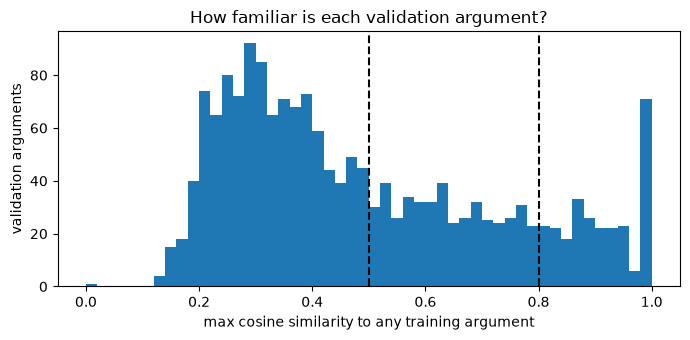

In [2]:
sim, nn = max_sim_to_train(X_tr, X_va)
va_df = va_df.assign(max_sim=sim, bucket=bucket(sim, NEAR_DUP_LOW, NEAR_DUP_HIGH))
print(va_df.bucket.value_counts())
plt.figure(figsize=(7, 3.5)); plt.hist(sim, bins=50)
for t in [NEAR_DUP_LOW, NEAR_DUP_HIGH]: plt.axvline(t, c="k", ls="--")
plt.xlabel("max cosine similarity to any training argument"); plt.ylabel("validation arguments")
plt.title("How familiar is each validation argument?"); plt.tight_layout()
plt.savefig(FIGURES / "val_max_similarity.png", dpi=150); plt.show()

In [3]:
rows = []
for f, m in models.items():
    P = m.predict(B)
    for b in ["template-seen", "intermediate", "novel"]:
        msk = (va_df.bucket == b).values
        s_ = scores(Y_va[msk], P[msk])
        lo, hi = bootstrap_ci(Y_va[msk], P[msk], "micro_f1", n_boot=500)
        rows.append({"model": f, "bucket": b, "n": int(msk.sum()), "micro_f1": s_["micro_f1"],
                     "micro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]", "macro_f1": s_["macro_f1"]})
overlap = pd.DataFrame(rows); overlap.round(3)

,model,bucket,n,micro_f1,micro_f1_95ci,macro_f1
0,LinearSVM,template-seen,266,0.952,"[0.931, 0.970]",0.871
1,LinearSVM,intermediate,443,0.921,"[0.900, 0.941]",0.861
2,LinearSVM,novel,1059,0.785,"[0.769, 0.801]",0.666
3,LR-L1,template-seen,266,0.953,"[0.930, 0.972]",0.870
4,LR-L1,intermediate,443,0.912,"[0.890, 0.931]",0.843
5,LR-L1,novel,1059,0.757,"[0.741, 0.774]",0.664
6,LR-L2,template-seen,266,0.946,"[0.925, 0.965]",0.859
7,LR-L2,intermediate,443,0.916,"[0.894, 0.936]",0.861
8,LR-L2,novel,1059,0.776,"[0.758, 0.791]",0.640


Micro-F1 is reported with a bootstrap 95% interval because the novel bucket is small and
macro-F1 there is computed over classes with only a handful of examples. A clear gap between
*template-seen* and *novel* means the headline score partly measures memorised templates.

## 6.2 Coefficient anatomy
For each label we sum the **positive** coefficients (the weights that push towards
predicting the fallacy) by token group, and compare with each group's share of the vocabulary.

In [4]:
anat = {}
for f, m in models.items():
    W, b = sc.linear_coefs(m)
    tab, base, groups = sc.coefficient_anatomy(W, vocab, LABELS)
    anat[f] = tab
print("vocabulary share by group:", {k: round(v, 3) for k, v in base.items()})
summary = pd.DataFrame({f: t[[f"pos_mass_{g}" for g in sc.GROUPS]].mean() for f, t in anat.items()}).T
summary.columns = sc.GROUPS; summary.round(3)

vocabulary share by group: {'topic': 0.892, 'cue': 0.056, 'function': 0.051}


,topic,cue,function
LinearSVM,0.826,0.081,0.092
LR-L1,0.795,0.104,0.101
LR-L2,0.820,0.082,0.098


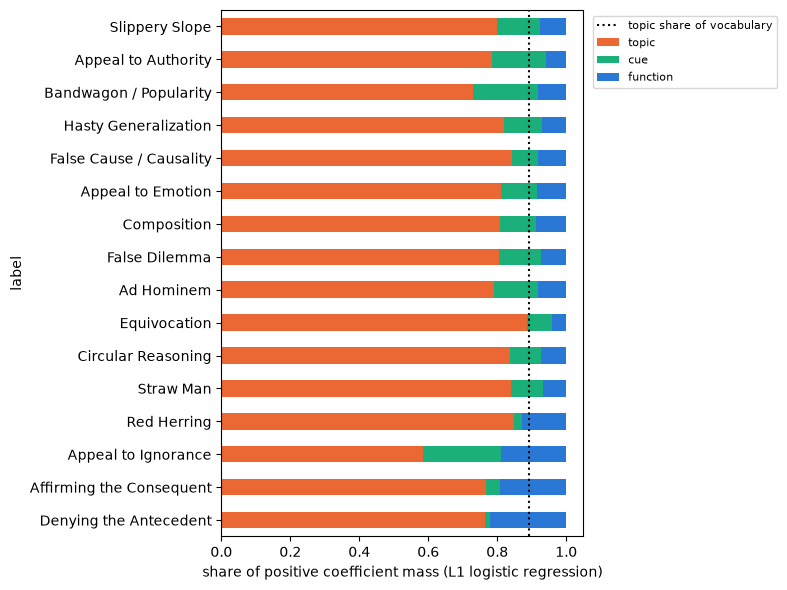

In [5]:
l1 = anat["LR-L1"].set_index("label")
ax = l1[[f"pos_mass_{g}" for g in sc.GROUPS]].rename(columns=lambda c: c.replace("pos_mass_", "")) \
    .plot.barh(stacked=True, figsize=(8, 6), color=["#eb6834", "#1baf7a", "#2a78d6"])
ax.axvline(base["topic"], c="k", ls=":", label="topic share of vocabulary")
ax.set_xlabel("share of positive coefficient mass (L1 logistic regression)"); ax.invert_yaxis()
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout()
plt.savefig(FIGURES / "coef_mass_by_group_l1.png", dpi=150); plt.show()

In [6]:
W1, _ = sc.linear_coefs(models["LR-L1"])
tops = sc.top_tokens(W1, vocab, LABELS, n=10)
pd.DataFrame({lab: [f"{t} ({g[0]})" for t, w, g in v] + [""] * (10 - len(v)) for lab, v in tops.items()}).T

,0,1,2,3,4,5,6,7,8,9
Slippery Slope,slope (t),eventually (c),addicted (t),is unsafe (t),soon (c),where a (f),meteorologist predicted (t),poisoning (t),all old (t),study shows (t)
Appeal to Authority,famous (c),professor (c),renowned (t),who has (f),testimony (t),expert (c),elon (t),educators (t),most secure (t),endorses (t)
Bandwagon / Popularity,everyone at (c),trending (c),everyone on (c),everyone in (c),everyone is (c),adopt ai (t),outcast (t),are drinking (t),agreed (t),everyone (c)
Hasty Generalization,amazing for (t),weight on (t),obviously all (c),performance for (t),basketball player (t),inaccurate (t),are obviously (c),all (c),and violent (t),loss therefore (t)
False Cause / Causality,caused (c),it while (f),concerns are (t),magically (t),directly (t),is causing (t),mailman must (t),made the (f),to drain (t),successful too (t)
Appeal to Emotion,heartbreaking (t),think of (c),because ignoring (t),imagine (c),our beloved (t),emotion (t),feel (c),joy (t),that poor (t),into technological (t)
Composition,each (c),flawed ideas (t),warming because (t),dissent (t),young entrepreneurs (t),study where (t),entire (c),be financially (t),ants (t),individual (t)
False Dilemma,either (c),or (c),else you're (t),will quickly (t),national security (t),amazing since (t),sacrifice all (t),or he (c),wanted so (t),from financial (t)
Ad Hominem,always wrong (t),wrong before (t),corrupt politicians (t),nutritionists who (t),banning them (t),was once (f),about public (t),can never (c),clearly lacks (t),paid (t)
Equivocation,light (t),means (c),bright (t),need more (t),popular now (c),process data (t),compete in (t),are powered (t),musicians (t),vapor (t)


(t) = topic, (c) = cue, (f) = function. Read the table label by label: a row dominated by (t)
tokens is a label the model recognises by *subject matter*.

**Important caveat about the lexicon.** "topic" is the *residual* group: every word that is
not in the cue lexicon or the stop-word list. The lexicon is small (≈150 words) and was fixed
before modelling, so some genuinely rhetorical words land in "topic" (e.g. *heartbreaking*,
*can't prove*, *always wrong*, *secretly*). We deliberately do **not** patch the lexicon after
seeing these weights, because that would tune the measurement to the result. Consequently the
topic share below is an **upper bound** on reliance on subject-matter artefacts, and the
cue share is a lower bound on reliance on rhetorical cues. The substitution test in 6.6 uses
a random-word control to separate the two effects.

In [7]:
import re
name_patterns = {"Slippery Slope": r"slippery slope", "Bandwagon / Popularity": r"bandwagon",
                 "Circular Reasoning": r"circular", "Appeal to Authority": r"appeal to authority",
                 "Ad Hominem": r"ad hominem", "Straw Man": r"straw ?man", "Red Herring": r"red herring",
                 "False Dilemma": r"false dilemma|false dichotomy"}
print("Arguments that literally contain the fallacy's name (whole dataset):")
for lab, pat in name_patterns.items():
    hit = df.argument.str.contains(pat, case=False, regex=True)
    print(f"  {lab:24s} {hit.sum():4d} rows, of which {df.loc[hit, lab].mean() if hit.any() else 0:.0%} carry that label")
#
# ## 6.3 Input masking at prediction time
# The models above are trained on full text. At prediction time we delete one group of tokens
# from every validation argument and measure the damage.

Arguments that literally contain the fallacy's name (whole dataset):
  Slippery Slope             45 rows, of which 98% carry that label
  Bandwagon / Popularity      6 rows, of which 50% carry that label
  Circular Reasoning          4 rows, of which 50% carry that label
  Appeal to Authority         2 rows, of which 100% carry that label
  Ad Hominem                  0 rows, of which 0% carry that label
  Straw Man                   0 rows, of which 0% carry that label
  Red Herring                 0 rows, of which 0% carry that label


  False Dilemma               0 rows, of which 0% carry that label


In [8]:
variants = {
    "full text": ["topic", "cue", "function"],
    "no topic words (cue + function only)": ["cue", "function"],
    "no cue words": ["topic", "function"],
    "no function words": ["topic", "cue"],
    "topic words only": ["topic"],
}
mrows = []
for name, keep in variants.items():
    Bm = vec.transform(sc.mask_texts(X_va, keep))
    for f, m in models.items():
        mrows.append({"input": name, "model": f, **{k: v for k, v in scores(Y_va, m.predict(Bm)).items()
                                                    if k in ("macro_f1", "micro_f1")}})
masking = pd.DataFrame(mrows).drop_duplicates(["input", "model"])
masking.pivot(index="input", columns="model", values="macro_f1").loc[list(dict.fromkeys(variants))].round(3)

model,LR-L1,LR-L2,LinearSVM
input,,,
full text,0.816,0.811,0.823
no topic words (cue + function only),0.623,0.637,0.652
no cue words,0.686,0.723,0.735
no function words,0.632,0.679,0.681
topic words only,0.493,0.533,0.502


## 6.4 Group-restricted retraining
Masking a trained model penalises it for a distribution shift it never saw. A fairer
question is: *if a model is trained and evaluated with only one token group, how well can it
do?* The vectoriser is re-fitted on the masked training text each time.

In [9]:
rrows = []
for name, keep in variants.items():
    v = word_tfidf(ngram_range=(1, 2))
    Ar = v.fit_transform(sc.mask_texts(X_tr, keep)); Br = v.transform(sc.mask_texts(X_va, keep))
    m = build("LinearSVM").fit(Ar, Y_tr); P = m.predict(Br)
    rrows.append({"trained & evaluated on": name, "vocab": Ar.shape[1], **{k: v_ for k, v_ in scores(Y_va, P).items()
                                                                       if k in ("macro_f1", "micro_f1")}})
restricted = pd.DataFrame(rrows); restricted.round(3)

,trained & evaluated on,vocab,micro_f1,macro_f1
0,full text,38246,0.833,0.823
1,no topic words (cue + function only),8931,0.771,0.747
2,no cue words,35608,0.808,0.792
3,no function words,30304,0.819,0.790
4,topic words only,25129,0.771,0.744


## 6.5 Proper-noun masking (proposal: remove named entities)
`mask_proper_nouns` replaces mid-sentence capitalised words (Dr, Smith, Harvard, Tesla…) with
a placeholder. It is a fixed, stateless rule, so applying it to train and val cannot leak.

In [10]:
print(mask_proper_nouns(X_va.iloc[3]))
prow = []
for masked in [False, True]:
    tr = [mask_proper_nouns(x) for x in X_tr] if masked else X_tr
    va = [mask_proper_nouns(x) for x in X_va] if masked else X_va
    v = word_tfidf(ngram_range=(1, 2)); Ap = v.fit_transform(tr); Bp = v.transform(va)
    for f in ["LinearSVM", "LR-L1"]:
        P = build(f).fit(Ap, Y_tr).predict(Bp)
        prow.append({"proper nouns masked": masked, "model": f, **{k: v_ for k, v_ in scores(Y_va, P).items()
                                                                 if k in ("macro_f1", "micro_f1")}})
pd.DataFrame(prow).round(4)

All my friends say this new restaurant is amazing because famous chef propername propername recommended it, and honestly if you don't think it's the best food you've ever had, you clearly have terrible taste in everything about life.


,proper nouns masked,model,micro_f1,macro_f1
0,False,LinearSVM,0.8335,0.8229
1,False,LR-L1,0.8132,0.8155
2,True,LinearSVM,0.8326,0.8235
3,True,LR-L1,0.8114,0.8147


## 6.6 Substitution stress tests
For every validation argument and every label it truly has **and** the model currently
predicts, we apply a label-preserving edit and check whether the prediction flips to negative.

* **Topic swap (top-weighted):** replace the 3 topic words with the largest positive weight
  for that label by "neutral" topic words (frequent in train, near-zero weight for all labels).
  Changing what an argument is *about* should not change its fallacy type.
* **Topic swap (random control):** replace 3 random topic words, to separate "the model relies
  on specific topic words" from "any edit perturbs the model".
* **Cue synonym swap:** replace cue words by rare synonyms (eventually→ultimately,
  expert→specialist, idiot→imbecile, …). The fallacy is unchanged; a flip means the model
  memorised a string rather than the concept.

In [11]:
df_counts = np.asarray((A > 0).sum(axis=0)).ravel()
def stress(model, family, texts, Y):
    W, b = sc.linear_coefs(model)
    pool = sc.neutral_topic_pool(W, vocab, df_counts)
    base_pred = model.predict(vec.transform(texts))
    ii, kk = np.where((Y == 1) & (base_pred == 1))          # true positives only
    t_sub = [texts.iloc[i] if hasattr(texts, "iloc") else texts[i] for i in ii]
    out = []
    for name, (new, nsw) in {
        "topic swap (top-weighted)": sc.topic_substitution(t_sub, kk, W, vidx, pool, 3, "top"),
        "topic swap (random control)": sc.topic_substitution(t_sub, kk, W, vidx, pool, 3, "random"),
        "cue synonym swap": sc.cue_synonym_swap(t_sub),
    }.items():
        P = model.predict(vec.transform(new))
        flipped = P[np.arange(len(kk)), kk] == 0
        edited = nsw > 0
        out.append({"model": family, "test": name, "true positives": len(kk),
                    "edited": int(edited.sum()),
                    "flip rate (edited)": float(flipped[edited].mean()) if edited.any() else np.nan})
    return out, pool

srows = []
for f in ["LinearSVM", "LR-L1"]:
    r, pool = stress(models[f], f, X_va, Y_va); srows += r
stress_df = pd.DataFrame(srows); print("neutral pool sample:", pool[:15]); stress_df.round(3)

neutral pool sample: ['youth', 'abilities', 'ability', 'able', 'mathematics', 'mary', 'maria', 'arithmetic', 'drained', 'simply', 'skilled', 'missed', 'silent', 'everyday', 'significantly']


,model,test,true positives,edited,flip rate (edited)
0,LinearSVM,topic swap (top-weighted),1942,1940,0.231
1,LinearSVM,topic swap (random control),1942,1941,0.060
2,LinearSVM,cue synonym swap,1942,1458,0.093
3,LR-L1,topic swap (top-weighted),1861,1793,0.243
4,LR-L1,topic swap (random control),1861,1861,0.080
5,LR-L1,cue synonym swap,1861,1386,0.127


## 6.7 Save for notebook 08 and the website

In [12]:
out = {"val_overlap": overlap.to_dict("records"), "val_masking": masking.to_dict("records"),
       "val_restricted": restricted.to_dict("records"), "val_stress": stress_df.to_dict("records"),
       "proper_noun_ablation": prow,
       "coef_mass_mean": summary.reset_index().rename(columns={"index": "model"}).to_dict("records"),
       "vocab_group_share": base}
(RESULTS / "shortcut_val.json").write_text(json.dumps(out, indent=2, default=float)); print("saved")

saved
